In [ ]:
import tensorflow as tf
import cv2
import os
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
import zipfile
with zipfile.ZipFile('/content/archive (3).zip', 'r') as zip_ref:
  zip_ref.extractall('/content/dataset')

# This dataset's zip has a duplicated images/images/... folder inside it,
# so find the real train/validation folders instead of hardcoding a path.
TRAIN_DIR = VAL_DIR = None
for root, dirs, files in os.walk('/content/dataset'):
    if os.path.basename(root) == 'train' and dirs:
        TRAIN_DIR = root
    if os.path.basename(root) == 'validation' and dirs:
        VAL_DIR = root
print(TRAIN_DIR, VAL_DIR)

/content/dataset/images/train /content/dataset/images/validation


In [ ]:
sample_file = os.listdir(f"{TRAIN_DIR}/angry")[0]
img_array = cv2.imread(f"{TRAIN_DIR}/angry/{sample_file}")

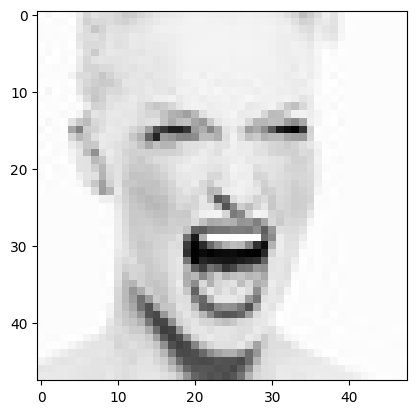

In [ ]:
plt.imshow(cv2.cvtColor(img_array, cv2.COLOR_BGR2RGB))

In [ ]:
datedirectory = "dataset/train"

In [ ]:
# Fixed: must match train_data.class_names exactly (this dataset's folders
# are lowercase, and alphabetical order puts Neutral before Sad/Surprise).
# This was the cause of wrong webcam predictions.
Classes = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]

In [ ]:
IMG_SIZE  = 224 ## imagenet 224 size
BATCH_SIZE = 32 # number of images per batch

In [ ]:
#Load training images
train_data = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size = (IMG_SIZE,IMG_SIZE),
    batch_size = BATCH_SIZE,
    color_mode = "rgb",
    shuffle= True
)

Found 28821 files belonging to 7 classes.


In [ ]:

val_data = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    shuffle=False
)

Found 7066 files belonging to 7 classes.


In [ ]:
#show class names (emotions)
class_names = train_data.class_names

print("Classes:" , class_names)
print("Number of Classes:" , len(class_names))

assert class_names == Classes, "class order mismatch — fix the Classes list above"

import json
with open("labels.json", "w") as f:
    json.dump(class_names, f)

Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Number of Classes: 7


In [ ]:
preprocess = tf.keras.applications.mobilenet_v2.preprocess_input

train_data = train_data.map(
    lambda x, y: (preprocess(x), y)
)

val_data = val_data.map(
    lambda x, y: (preprocess(x), y)
)

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_data = train_data.prefetch(AUTOTUNE)
val_data = val_data.prefetch(AUTOTUNE)

In [ ]:
print("GPU:", tf.config.list_physical_devices("GPU"))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet",
    pooling="avg"
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
#feature extractor
base_model.trainable = False
print("MobileNetV2 is frozen.")
print("Feature size:", base_model.output_shape)

MobileNetV2 is frozen.
Feature size: (None, 1280)


In [ ]:
def extract_features(dataset):

    features = []
    labels = []

    for images, labels_batch in dataset:

        # MobileNetV2 extracts features
        batch_features = base_model(
            images,
            training=False
        )

        features.append(batch_features.numpy())
        labels.append(labels_batch.numpy())

    features = np.concatenate(features)
    labels = np.concatenate(labels)

    return features, labels

In [ ]:
print("Extracting training features...")

X_train, y_train = extract_features(train_data)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

Extracting training features...
X_train: (28821, 1280)
y_train: (28821,)


In [ ]:
print("Extracting validation features...")

X_val, y_val = extract_features(val_data)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

Extracting validation features...
X_val: (7066, 1280)
y_val: (7066,)


In [ ]:
for i, name in enumerate(class_names):
    count = np.sum(y_train == i)
    print(name, count)

angry 3993
disgust 436
fear 4103
happy 7164
neutral 4982
sad 4938
surprise 3205


In [ ]:
classifier = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(1280,)),

    tf.keras.layers.Dense(
        128,
        activation="relu"
    ),

    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(
        64,
        activation="relu"
    ),

    tf.keras.layers.Dense(
        7,
        activation="softmax"
    )
])

In [ ]:
# inputs = tf.keras.Input(
#     shape=(IMG_SIZE, IMG_SIZE, 3)
# )

# x = base_model(inputs, training=False)

# x = tf.keras.layers.Dense(
#     128,
#     activation="relu"
# )(x)

# x = tf.keras.layers.Dropout(0.3)(x)

# x = tf.keras.layers.Dense(
#     64,
#     activation="relu"
# )(x)

# outputs = tf.keras.layers.Dense(
#     7,
#     activation="softmax"
# )(x)

# new_model = tf.keras.Model(
#     inputs=inputs,
#     outputs=outputs
# )

In [ ]:
# new_model.compile(
#     optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
#     loss="sparse_categorical_crossentropy",
#     metrics=["accuracy"]
# )

In [ ]:
classifier.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
# history = new_model.fit(
#     train_data,
#     validation_data=val_data,
#     epochs=3
# )

NameError: name 'new_model' is not defined

In [ ]:
# Dataset is imbalanced (e.g. disgust has ~16x fewer images than happy),
# which biases the model toward the majority classes. class_weight corrects
# for this during training with no architecture changes.
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights))
print(class_weight_dict)

{0: np.float64(1.031125898894494), 1: np.float64(9.443315858453474), 2: np.float64(1.0034817729187702), 3: np.float64(0.5747188322565207), 4: np.float64(0.8264322991340254), 5: np.float64(0.8337962159347335), 6: np.float64(1.2846445286382884)}


In [ ]:
checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "best_classifier.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max"
)

history = classifier.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=64,
    class_weight=class_weight_dict,
    callbacks=[checkpoint]
)

Epoch 1/15
451/451 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.3089 - loss: 1.7423 - val_accuracy: 0.3313 - val_loss: 1.6852
Epoch 2/15
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3842 - loss: 1.5692 - val_accuracy: 0.4708 - val_loss: 1.4315
Epoch 3/15
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4181 - loss: 1.4781 - val_accuracy: 0.4645 - val_loss: 1.4330
Epoch 4/15
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4337 - loss: 1.4265 - val_accuracy: 0.4707 - val_loss: 1.3724
Epoch 5/15
451/451 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.4468 - loss: 1.3906 - val_accuracy: 0.4684 - val_loss: 1.4135
Epoch 6/15
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4553 - loss: 1.3580 - val_accuracy: 0.4567 - val_loss: 1.4206
Epoch 7/15
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4618 - loss: 1.3214 - val_accuracy: 0.4875 - val_loss: 1.3611
Epoch 8/15
451/451 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.4717 - loss: 1.2856 - val_accuracy: 0.

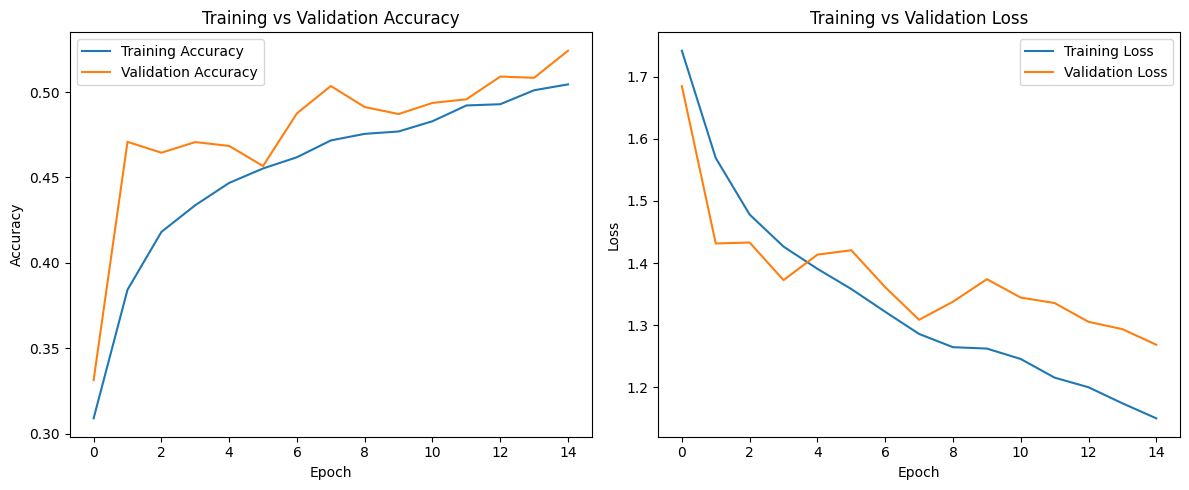

In [ ]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()


plt.subplot(1, 2, 2)

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
print("Best validation accuracy:",
      max(history.history["val_accuracy"]))

Best validation accuracy: 0.5242003798484802


In [ ]:
print("Final training accuracy:",
      history.history["accuracy"][-1])

print("Final validation accuracy:",
      history.history["val_accuracy"][-1])

Final training accuracy: 0.504493236541748
Final validation accuracy: 0.5242003798484802


In [ ]:
print("Best validation accuracy:",
      max(history.history["val_accuracy"]))

Best validation accuracy: 0.5242003798484802


In [ ]:
print("Best validation accuracy:",
      max(history.history["val_accuracy"]))

print("Best validation epoch:",
      np.argmax(history.history["val_accuracy"]) + 1)

Best validation accuracy: 0.5242003798484802
Best validation epoch: 15


In [ ]:
final_model = tf.keras.Sequential([
    base_model,
    classifier
])

In [ ]:
final_model.save("face_emotion_model.keras")

In [ ]:
print("Model saved successfully!")

Model saved successfully!


Actual: angry
Predicted: neutral
Confidence: 37.90%


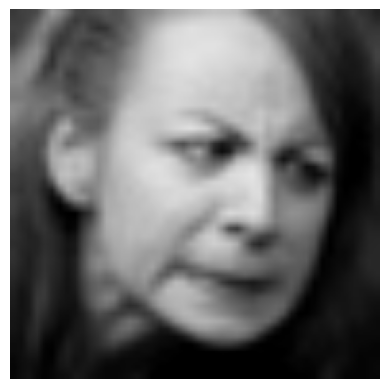

In [ ]:
for images, labels in val_data.take(1):

    image = images[0]
    true_label = labels[0].numpy()

    prediction = final_model.predict(
        tf.expand_dims(image, axis=0),
        verbose=0
    )

    predicted_label = np.argmax(prediction[0])
    confidence = prediction[0][predicted_label]

    print("Actual:", class_names[true_label])
    print("Predicted:", class_names[predicted_label])
    print("Confidence:", f"{confidence:.2%}")

    plt.imshow(
        tf.cast((image + 1) * 127.5, tf.uint8)
    )
    plt.axis("off")
    plt.show()

    break

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

y_true = []
y_pred = []

for images, labels in val_data:

    predictions = final_model.predict(images, verbose=0)

    # Your labels are integer encoded
    y_true.extend(labels.numpy())

    # Convert prediction probabilities to class number
    y_pred.extend(np.argmax(predictions, axis=1))

class_names = [
    "Angry",
    "Disgust",
    "Fear",
    "Happy",
    "Neutral",
    "Sad",
    "Surprise"
]

print("Classification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

cm = confusion_matrix(y_true, y_pred)

print("\nConfusion Matrix:")
print(cm)

Classification Report:
              precision    recall  f1-score   support

       Angry     0.4286    0.3469    0.3834       960
     Disgust     0.3892    0.5856    0.4676       111
        Fear     0.4317    0.3261    0.3716      1018
       Happy     0.6760    0.7397    0.7064      1825
     Neutral     0.4494    0.5329    0.4876      1216
         Sad     0.4082    0.4276    0.4177      1139
    Surprise     0.6782    0.6136    0.6443       797

    accuracy                         0.5242      7066
   macro avg     0.4945    0.5103    0.4969      7066
weighted avg     0.5208    0.5242    0.5193      7066


Confusion Matrix:
[[ 333   25   91  154  169  153   35]
 [   7   65    6    8   11    9    5]
 [ 118   17  332  110  156  192   93]
 [  70   14   51 1350  160  136   44]
 [  87   12   63  172  648  196   38]
 [ 133   29  124  136  213  487   17]
 [  29    5  102   67   85   20  489]]


In [ ]:
from google.colab import files

files.download("face_emotion_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# early_stop = tf.keras.callbacks.EarlyStopping(
#     monitor="val_loss",
#     patience=2,
#     restore_best_weights=True
# )
# history = new_model.fit(
#     train_data,
#     validation_data=val_data,
#     epochs=15,
#     callbacks=[early_stop]
# )

Epoch 1/15
898/898 ━━━━━━━━━━━━━━━━━━━━ 32s 35ms/step - accuracy: 0.5283 - loss: 1.2427 - val_accuracy: 0.4951 - val_loss: 1.3227
Epoch 2/15
898/898 ━━━━━━━━━━━━━━━━━━━━ 31s 34ms/step - accuracy: 0.5373 - loss: 1.2238 - val_accuracy: 0.4982 - val_loss: 1.2981
Epoch 3/15
898/898 ━━━━━━━━━━━━━━━━━━━━ 33s 37ms/step - accuracy: 0.5446 - loss: 1.2013 - val_accuracy: 0.5085 - val_loss: 1.2803
Epoch 4/15
898/898 ━━━━━━━━━━━━━━━━━━━━ 31s 35ms/step - accuracy: 0.5471 - loss: 1.1859 - val_accuracy: 0.5174 - val_loss: 1.2865
Epoch 5/15
898/898 ━━━━━━━━━━━━━━━━━━━━ 32s 36ms/step - accuracy: 0.5533 - loss: 1.1699 - val_accuracy: 0.5013 - val_loss: 1.2969


In [ ]:
# print(tf.config.list_physical_devices())

[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


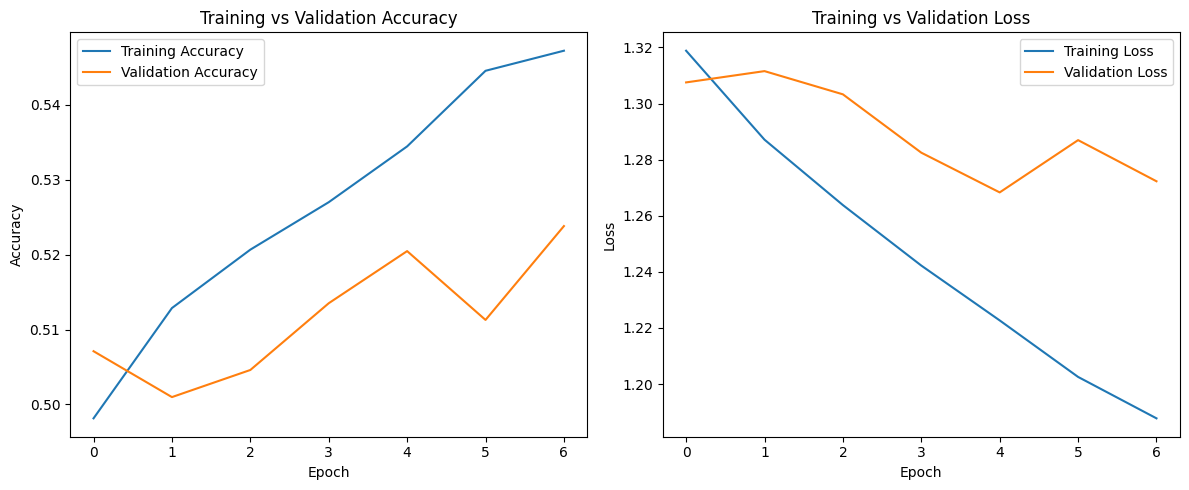

In [ ]:
# plt.figure(figsize=(12, 5))

# # Accuracy
# plt.subplot(1, 2, 1)

# plt.plot(
#     history.history["accuracy"],
#     label="Training Accuracy"
# )

# plt.plot(
#     history.history["val_accuracy"],
#     label="Validation Accuracy"
# )

# plt.xlabel("Epoch")
# plt.ylabel("Accuracy")
# plt.title("Training vs Validation Accuracy")
# plt.legend()


# # Loss
# plt.subplot(1, 2, 2)

# plt.plot(
#     history.history["loss"],
#     label="Training Loss"
# )

# plt.plot(
#     history.history["val_loss"],
#     label="Validation Loss"
# )

# plt.xlabel("Epoch")
# plt.ylabel("Loss")
# plt.title("Training vs Validation Loss")
# plt.legend()

# plt.tight_layout()
# plt.show()

In [ ]:
# for images, labels in val_data.take(1):

#     image = images[0]
#     true_label = labels[0]

#     prediction = new_model.predict(
#         tf.expand_dims(image, axis=0)
#     )

#     predicted_class = np.argmax(prediction[0])
#     confidence = prediction[0][predicted_class]

#     print("Actual:", class_names[true_label])
#     print("Predicted:", class_names[predicted_class])
#     print("Confidence:", f"{confidence:.2%}")

#     break

NameError: name 'new_model' is not defined

In [ ]:
# new_model.save("/content/face_emotion_model.keras")  # new_model is never defined above (commented out)

In [ ]:
base_model.trainable = True

FINE_TUNE_AT = len(base_model.layers) - 40  # unfreeze roughly the last 40 layers
for layer in base_model.layers[:FINE_TUNE_AT]:
    layer.trainable = False

print(f"Fine-tuning {sum(l.trainable for l in base_model.layers)} of {len(base_model.layers)} MobileNetV2 layers")

Fine-tuning 40 of 155 MobileNetV2 layers


In [ ]:
final_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
finetune_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "face_emotion_model_finetuned.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max"
)

history_finetune = final_model.fit(
    train_data,
    validation_data=val_data,
    epochs=10,
    class_weight=class_weight_dict,
    callbacks=[finetune_checkpoint]
)

Epoch 1/10
901/901 ━━━━━━━━━━━━━━━━━━━━ 90s 76ms/step - accuracy: 0.3050 - loss: 2.2757 - val_accuracy: 0.4434 - val_loss: 1.4639
Epoch 2/10
901/901 ━━━━━━━━━━━━━━━━━━━━ 48s 53ms/step - accuracy: 0.3659 - loss: 1.5375 - val_accuracy: 0.4178 - val_loss: 1.4972
Epoch 3/10
901/901 ━━━━━━━━━━━━━━━━━━━━ 44s 49ms/step - accuracy: 0.4194 - loss: 1.4032 - val_accuracy: 0.4455 - val_loss: 1.4404
Epoch 4/10
901/901 ━━━━━━━━━━━━━━━━━━━━ 45s 49ms/step - accuracy: 0.4579 - loss: 1.3009 - val_accuracy: 0.4674 - val_loss: 1.3913
Epoch 5/10
901/901 ━━━━━━━━━━━━━━━━━━━━ 44s 48ms/step - accuracy: 0.4895 - loss: 1.2189 - val_accuracy: 0.5017 - val_loss: 1.3177
Epoch 6/10
901/901 ━━━━━━━━━━━━━━━━━━━━ 48s 53ms/step - accuracy: 0.5113 - loss: 1.1524 - val_accuracy: 0.5110 - val_loss: 1.2981
Epoch 7/10
901/901 ━━━━━━━━━━━━━━━━━━━━ 79s 49ms/step - accuracy: 0.5307 - loss: 1.0850 - val_accuracy: 0.5269 - val_loss: 1.2672
Epoch 8/10
901/901 ━━━━━━━━━━━━━━━━━━━━ 43s 48ms/step - accuracy: 0.5467 - loss: 1.0488 - 

In [ ]:
print("Best fine-tuned val accuracy:", max(history_finetune.history["val_accuracy"]))

Best fine-tuned val accuracy: 0.5543447732925415


In [ ]:
print(history_finetune.history["val_accuracy"])

[0.4433908760547638, 0.4177752733230591, 0.4455137252807617, 0.46744975447654724, 0.5016982555389404, 0.5110387802124023, 0.5268893241882324, 0.5369374752044678, 0.5498160123825073, 0.5543447732925415]


In [ ]:
final_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_accuracy", patience=5, restore_best_weights=True, mode="max"
)

history_finetune = final_model.fit(
    train_data,
    validation_data=val_data,
    epochs=20,
    class_weight=class_weight_dict,
    callbacks=[finetune_checkpoint, early_stop]
)

Epoch 1/20
901/901 ━━━━━━━━━━━━━━━━━━━━ 45s 50ms/step - accuracy: 0.6409 - loss: 0.8398 - val_accuracy: 0.5764 - val_loss: 1.1575
Epoch 2/20
901/901 ━━━━━━━━━━━━━━━━━━━━ 44s 49ms/step - accuracy: 0.6520 - loss: 0.8080 - val_accuracy: 0.5805 - val_loss: 1.1585
Epoch 3/20
901/901 ━━━━━━━━━━━━━━━━━━━━ 45s 50ms/step - accuracy: 0.6629 - loss: 0.7827 - val_accuracy: 0.5868 - val_loss: 1.1454
Epoch 4/20
901/901 ━━━━━━━━━━━━━━━━━━━━ 48s 53ms/step - accuracy: 0.6737 - loss: 0.7481 - val_accuracy: 0.5916 - val_loss: 1.1351
Epoch 5/20
901/901 ━━━━━━━━━━━━━━━━━━━━ 48s 53ms/step - accuracy: 0.6895 - loss: 0.7207 - val_accuracy: 0.5834 - val_loss: 1.1533
Epoch 6/20
901/901 ━━━━━━━━━━━━━━━━━━━━ 48s 53ms/step - accuracy: 0.7011 - loss: 0.6967 - val_accuracy: 0.5988 - val_loss: 1.1385
Epoch 7/20
901/901 ━━━━━━━━━━━━━━━━━━━━ 82s 53ms/step - accuracy: 0.7142 - loss: 0.6598 - val_accuracy: 0.6023 - val_loss: 1.1462
Epoch 8/20
901/901 ━━━━━━━━━━━━━━━━━━━━ 44s 49ms/step - accuracy: 0.7320 - loss: 0.6347 - 

In [ ]:
print(history_finetune.history["val_accuracy"])


[0.5764223337173462, 0.5805264711380005, 0.5867534875869751, 0.5915652513504028, 0.5833569169044495, 0.5987828969955444, 0.6023209691047668, 0.5987828969955444, 0.6038777232170105, 0.601754903793335, 0.6028870940208435, 0.6024624705314636, 0.6052929759025574, 0.6004811525344849, 0.6055759787559509, 0.598075270652771, 0.6020379066467285, 0.6062836050987244, 0.6092556118965149, 0.6126521229743958]


In [ ]:
print("Best fine-tuned val accuracy:", max(history_finetune.history["val_accuracy"]))

Best fine-tuned val accuracy: 0.6126521229743958


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

y_true, y_pred = [], []
for images, labels in val_data:
    preds = final_model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(preds, axis=1))

print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
print(confusion_matrix(y_true, y_pred))

              precision    recall  f1-score   support

       Angry     0.5106    0.5021    0.5063       960
     Disgust     0.6737    0.5766    0.6214       111
        Fear     0.5180    0.4391    0.4753      1018
       Happy     0.8218    0.8011    0.8113      1825
     Neutral     0.4986    0.5855    0.5386      1216
         Sad     0.4876    0.5004    0.4939      1139
    Surprise     0.7513    0.7428    0.7470       797

    accuracy                         0.6127      7066
   macro avg     0.6088    0.5925    0.5991      7066
weighted avg     0.6160    0.6127    0.6131      7066

[[ 482   15   79   64  127  165   28]
 [  21   64    4    2    6    9    5]
 [ 136    5  447   41  138  183   68]
 [  68    2   33 1462  159   61   40]
 [ 101    3   80  115  712  167   38]
 [ 123    3  126   57  243  570   17]
 [  13    3   94   38   43   14  592]]


In [ ]:
print(len(history_finetune.history["val_accuracy"]))
print(history_finetune.history["val_accuracy"])

20
[0.5764223337173462, 0.5805264711380005, 0.5867534875869751, 0.5915652513504028, 0.5833569169044495, 0.5987828969955444, 0.6023209691047668, 0.5987828969955444, 0.6038777232170105, 0.601754903793335, 0.6028870940208435, 0.6024624705314636, 0.6052929759025574, 0.6004811525344849, 0.6055759787559509, 0.598075270652771, 0.6020379066467285, 0.6062836050987244, 0.6092556118965149, 0.6126521229743958]


In [ ]:
final_model.save("/content/face_emotion_model_final.keras")

In [ ]:
from google.colab import files

files.download("/content/face_emotion_model_finetuned.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import json

class_names = [
    "Angry",
    "Disgust",
    "Fear",
    "Happy",
    "Neutral",
    "Sad",
    "Surprise"
]

with open("/content/class_names.json", "w") as f:
    json.dump(class_names, f)

print("class_names.json created")

class_names.json created


In [ ]:
files.download("/content/class_names.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Save trained model
model.save("/content/food_quality_model.keras")

print("Model saved successfully!")

NameError: name 'model' is not defined